# COGS 109 Project Checkpoint 1: Your Regression Model

**Due Monday, October 26 at 11:59pm PT.** This notebook walks you through every step of Checkpoint 1, in the same order as the guidelines.

**Before you start**

- Make your own copy: **File → Save a copy in Drive**.
- Rename it with your name, for example `CP1_Ana_Lopez.ipynb`, and put it in your group's shared Google Drive folder. That folder is what your group submits.
- Edit the cells marked ✏️. Every other cell runs as is.

**What's in it**

| Step | Who | What you do |
| --- | --- | --- |
| 1. Choose your dataset | Group (same in every copy) | Load the data, look at every variable, check the outcome |
| 2. Shared train/test split | Group (same in every copy) | Split once with one seed, and check everyone has the same split |
| 3. Fit your model | You | Fit a multiple regression, write it in math, interpret it |
| 4. Check assumptions | You | Four assumptions, multicollinearity, outliers, leverage, and fixes |
| 5. Test your model | You | Test MSE and test R² |
| 6. Compare models | One member | Put everyone's results in one table |

**About the example data.** So you can see what every step produces, this notebook runs on `Carseats`: car seat sales at 400 stores, from the ISLP textbook. Replace it with your group's dataset in Step 1.

**Before you submit**, choose **Runtime → Restart and run all**. Your notebook must run from top to bottom without errors, and its figures must match your slides.

AI tools are allowed with a brief disclosure in your individual form. Make sure you can explain every line, because you'll be asked about your model in the oral exam.

In [32]:
# Setup (no need to edit)
import hashlib
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.model_selection import train_test_split
from IPython.display import display, Math, Markdown

plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

---
# Step 1. Choose your dataset (group)

Agree on Steps 1 and 2 as a group, then copy the **same** cells into every member's notebook.

Start from the approved datasets on the course's Datasets page. **Open the dataset and look at its variables before you choose it.** Don't pick it from the title alone.

### 1a. ✏️ Load your data

- `DATA_PATH`: in Colab, upload your file with the folder icon on the left and use its name (for example, `"my_data.csv"`), or paste a link to a raw CSV.
- `OUTCOME`: the column you will predict. It must be a **continuous quantitative** variable, a number that can take many values. A category or a yes/no variable needs classification, which comes later in the course.
- `OUTCOME_LABEL`: the axis label for every plot, **with units**.

In [33]:
# ✏️ EDIT: your group's dataset
DATA_PATH = "../data/online_shoppers_intention.csv"
OUTCOME = "ProductRelated_Duration"
OUTCOME_LABEL = "Time spent browsing product pages (seconds)"

df = pd.read_csv(DATA_PATH)
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [34]:
df.shape

(12330, 18)

### 1b. Look at every variable

This table lists every column with its type, number of distinct values, missing values, and an example. For each one, ask:

- Is it **quantitative** (a number you can do arithmetic on) or **qualitative** (a category, even if it's coded as a number, like 1 = urban, 2 = rural)?
- What are its units?
- How many values are missing?

In [35]:
overview = pd.DataFrame({
    "type": ["quantitative" if pd.api.types.is_numeric_dtype(df[c]) else "qualitative" for c in df.columns],
    "distinct values": df.nunique(),
    "missing": df.isna().sum(),
    "example": df.iloc[0],
})
overview

,type,distinct values,missing,example
Administrative,quantitative,27,0,0
Administrative_Duration,quantitative,3335,0,0.0
Informational,quantitative,17,0,0
Informational_Duration,quantitative,1258,0,0.0
ProductRelated,quantitative,311,0,1
ProductRelated_Duration,quantitative,9551,0,0.0
BounceRates,quantitative,1872,0,0.2
ExitRates,quantitative,4777,0,0.2
PageValues,quantitative,2704,0,0.0
SpecialDay,quantitative,6,0,0.0


### 1c. ✏️ Clean the data

- Drop rows with missing values, and drop columns you won't use (like an ID column).
- If a column is a category coded as numbers, convert it with `.astype(str)` so it's treated as qualitative.
- Keep this cell identical across your group.

In [36]:
# ✏️ EDIT: cleaning steps for your dataset
n_before = len(df)
df = df.dropna()
for c in ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend", "Revenue"]:
    df[c] = df[c].astype(str)

print(f"Dropped {n_before - len(df)} rows with missing values; {len(df)} rows remain.")

Dropped 0 rows with missing values; 12330 rows remain.


### Removing outliers using the 1.5 x IQR rule (Part 4d. revisted)

In [37]:
y = df["ProductRelated_Duration"]
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
df = df[(y >= q1 - 1.5 * iqr) & (y <= q3 + 1.5 * iqr)]

In [38]:
df.shape

(11369, 18)

### 1d. Check your dataset meets the requirements (Slide 1)

This checks the Checkpoint 1 requirements and prints the numbers for your dataset slide.

In [39]:
predictors = [c for c in df.columns if c != OUTCOME]
quant = [c for c in predictors if pd.api.types.is_numeric_dtype(df[c])]
qual = [c for c in predictors if c not in quant]

outcome_numeric = pd.api.types.is_numeric_dtype(df[OUTCOME])
outcome_values = df[OUTCOME].nunique()
checks = [
    ("Outcome is numeric", outcome_numeric),
    (f"Outcome takes many values ({outcome_values} distinct), so it's continuous", outcome_numeric and outcome_values > 20),
    (f"At least 3 quantitative predictors (you have {len(quant)})", len(quant) >= 3),
    (f"At least 1 qualitative predictor (you have {len(qual)})", len(qual) >= 1),
]
for label, ok in checks:
    print(("✅ " if ok else "❌ ") + label)

print(f"\nn = {len(df)} observations")
print(f"p = {len(predictors)} predictors: {len(quant)} quantitative, {len(qual)} qualitative")
print("Quantitative:", quant)
print("Qualitative: ", {c: sorted(df[c].astype(str).unique().tolist()) for c in qual})

✅ Outcome is numeric
✅ Outcome takes many values (8590 distinct), so it's continuous
✅ At least 3 quantitative predictors (you have 9)
✅ At least 1 qualitative predictor (you have 8)

n = 11369 observations
p = 17 predictors: 9 quantitative, 8 qualitative
Quantitative: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Qualitative:  {'Month': ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep'], 'OperatingSystems': ['1', '2', '3', '4', '5', '6', '7', '8'], 'Browser': ['1', '10', '11', '12', '13', '2', '3', '4', '5', '6', '7', '8', '9'], 'Region': ['1', '2', '3', '4', '5', '6', '7', '8', '9'], 'TrafficType': ['1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '3', '4', '5', '6', '7', '8', '9'], 'VisitorType': ['New_Visitor', 'Other', 'Returning_Visitor'], 'Weekend': ['False', 'True'], 'Revenue': ['False', 'True']}


✏️ **Write for Slide 1** (a few words each):

- **Source:**
- **Your modeling question, in one sentence:**

### 1e. Explore the data (Slide 2)

Look at the outcome, then at how it relates to each predictor. Pick one or two figures that motivated your models for Slide 2.

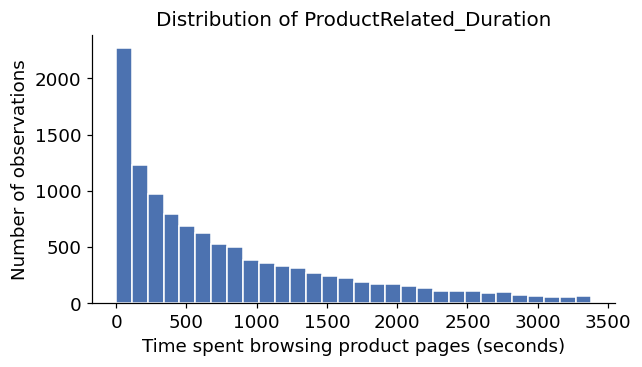

In [40]:
# Distribution of the outcome
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(df[OUTCOME], bins=30, color="#4C72B0", edgecolor="white")
ax.set(xlabel=OUTCOME_LABEL, ylabel="Number of observations", title=f"Distribution of {OUTCOME}")
plt.tight_layout()
plt.show()

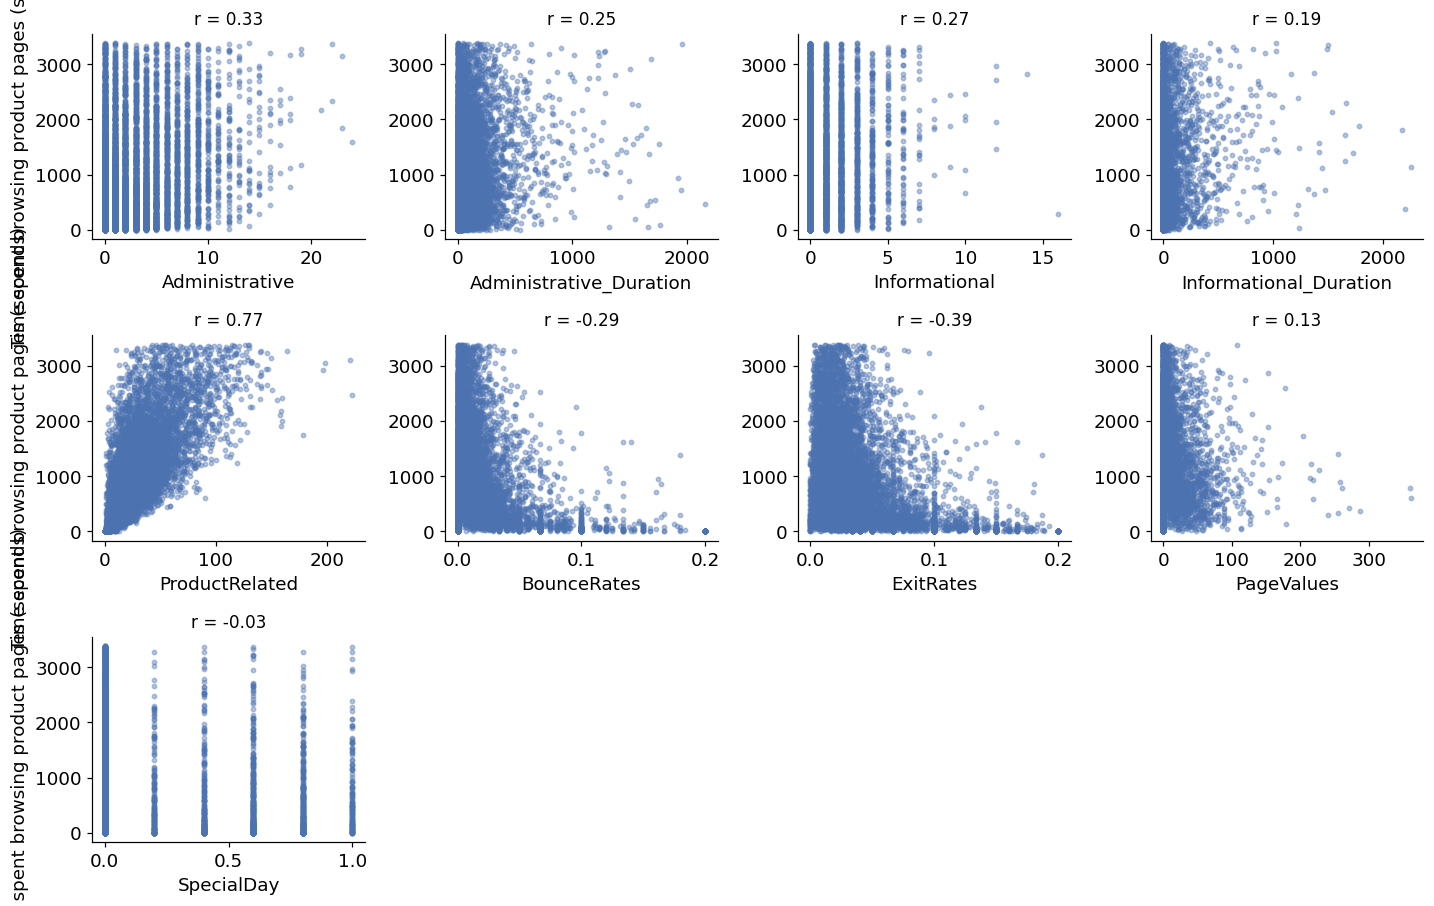

In [41]:
# The outcome against each quantitative predictor (r = correlation with the outcome)
ncol = 4
nrow = int(np.ceil(len(quant) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 2.8 * nrow), squeeze=False)
for ax, col in zip(axes.flat, quant):
    ax.scatter(df[col], df[OUTCOME], s=8, alpha=0.4, color="#4C72B0")
    ax.set_xlabel(col)
    ax.set_title(f"r = {df[col].corr(df[OUTCOME]):.2f}", fontsize=11)
for ax in axes.flat[len(quant):]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel(OUTCOME_LABEL)
plt.tight_layout()
plt.show()

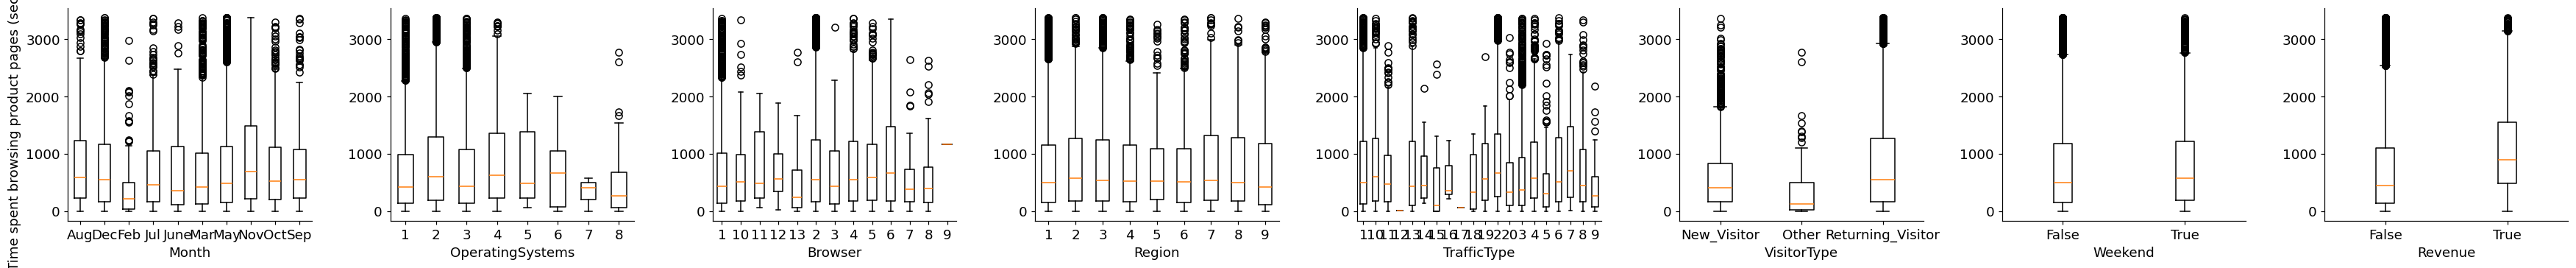

In [42]:
# The outcome within each category of each qualitative predictor
if qual:
    fig, axes = plt.subplots(1, len(qual), figsize=(4 * len(qual), 3.5), squeeze=False)
    for ax, col in zip(axes.flat, qual):
        levels = sorted(df[col].astype(str).unique())
        ax.boxplot([df.loc[df[col].astype(str) == lv, OUTCOME] for lv in levels])
        ax.set_xticks(range(1, len(levels) + 1), levels)
        ax.set_xlabel(col)
    axes[0, 0].set_ylabel(OUTCOME_LABEL)
    plt.tight_layout()
    plt.show()

---
# Step 2. Make one shared train/test split (group)

- Split the data **once**: about 80% for training and 20% for testing, with one random seed.
- Every member fits their model on `train` only. The `test` set is used once, in Step 5.
- Compare the **test set fingerprint** with your teammates before anyone fits a model. If it differs, someone's Step 1 or 2 doesn't match, and your test results can't be compared.

In [43]:
# ✏️ EDIT: agree on these as a group, then never change them
SEED = 109
TEST_FRACTION = 0.2

train, test = train_test_split(df, test_size=TEST_FRACTION, random_state=SEED)

fingerprint = hashlib.md5(str(sorted(test.index.tolist())).encode()).hexdigest()[:8]
print(f"Training set: {len(train)} rows | Test set: {len(test)} rows | random seed {SEED}")
print(f"Test set fingerprint: {fingerprint}   <- must match your teammates'")

Training set: 9095 rows | Test set: 2274 rows | random seed 109
Test set fingerprint: 39c7f0e1   <- must match your teammates'


### Helper functions (no need to edit)

These do the bookkeeping so you can focus on modeling. You should understand what each one computes, since you may be asked about it.

In [44]:
TRANSFORMS = {  # optional outcome transformations: (formula left side, back-transform to original units)
    "none":  (lambda y: y,                 lambda z: z),
    "log":   (lambda y: f"np.log({y})",    np.exp),
    "log1p": (lambda y: f"np.log1p({y})",  np.expm1),   # log(y + 1), for outcomes that include 0
    "sqrt":  (lambda y: f"np.sqrt({y})",   np.square),
}


def build_formula(rhs, transform="none"):
    """Turn a right-hand side like 'Price + C(ShelveLoc)' into a full statsmodels formula."""
    if transform == "log" and (df[OUTCOME] <= 0).any():
        raise ValueError(f"{OUTCOME} has values <= 0, so log() is undefined. Use 'log1p' or 'sqrt' instead.")
    if transform == "sqrt" and (df[OUTCOME] < 0).any():
        raise ValueError(f"{OUTCOME} has negative values, so sqrt() is undefined.")
    return f"{TRANSFORMS[transform][0](OUTCOME)} ~ {rhs}"


def back_transform(pred, transform):
    """Convert predictions back to the original units of the outcome."""
    return TRANSFORMS[transform][1](pred)


def mse(y, yhat):
    """Mean squared error: the average squared prediction error, in the outcome's units squared."""
    return float(np.mean((np.asarray(y) - np.asarray(yhat)) ** 2))


def r_squared(y, yhat):
    """1 - SSE/SST on whatever data you pass in. On the test set, this is test R^2."""
    y, yhat = np.asarray(y), np.asarray(yhat)
    return float(1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2))


def evaluate(model, transform):
    """Training and test MSE and R^2, all in the ORIGINAL units of the outcome."""
    pred_train = back_transform(model.predict(train), transform)
    pred_test = back_transform(model.predict(test), transform)
    return pd.Series({
        "train MSE": mse(train[OUTCOME], pred_train),
        "test MSE": mse(test[OUTCOME], pred_test),
        "train R2": r_squared(train[OUTCOME], pred_train),
        "test R2": r_squared(test[OUTCOME], pred_test),
    })


def model_quant_predictors(model):
    """Quantitative columns of the data that appear anywhere in the model."""
    names = " ".join(model.model.exog_names)
    return [q for q in quant if re.search(rf"\b{re.escape(q)}\b", names)]


def check_requirements(model):
    """Check your model against the Checkpoint 1 rules."""
    names = model.model.exog_names
    checks = [
        ("At least one quantitative predictor", len(model_quant_predictors(model)) >= 1),
        ("At least one qualitative predictor (shows up as a [T.level] coefficient)", any("[T." in n for n in names)),
    ]
    for label, ok in checks:
        print(("✅ " if ok else "❌ ") + label)
    print("⬜ Your set of predictors differs from your teammates' (check this together)")


# ---- writing the model in math -------------------------------------------------
_SUB = str.maketrans("0123456789", "₀₁₂₃₄₅₆₇₈₉")


def _pretty_term(name, latex):
    """'C(ShelveLoc)[T.Good]' -> ShelveLoc_Good, 'I(Price ** 2)' -> Price^2, 'A:B' -> A x B."""
    parts = []
    for piece in name.split(":"):
        m = re.match(r"C\((\w+).*?\)\[T\.(.+)\]", piece)
        if m:
            var, lvl = m.groups()
            parts.append(rf"\text{{{var}}}_{{\text{{{lvl}}}}}" if latex else f"{var}[{lvl}]")
            continue
        m = re.match(r"I\(\s*(.+?)\s*\*\*\s*(\d+)\s*\)", piece)
        if m:
            base, power = m.groups()
            parts.append(rf"\text{{{base}}}^{{{power}}}" if latex else f"{base}^{power}")
            continue
        m = re.match(r"np\.(log|log1p|sqrt)\((\w+)\)", piece)
        if m:
            fn, var = m.groups()
            fn = {"log": "log", "log1p": "log(1+", "sqrt": "√"}[fn]
            if latex:
                parts.append(rf"\log(\text{{{var}}})" if fn == "log" else
                             rf"\log(1+\text{{{var}}})" if fn.startswith("log(1") else rf"\sqrt{{\text{{{var}}}}}")
            else:
                parts.append(f"log({var})" if fn == "log" else f"log(1+{var})" if fn.startswith("log(1") else f"√{var}")
            continue
        parts.append(rf"\text{{{piece}}}" if latex else piece)
    return (r" \times " if latex else " × ").join(parts)


def _lhs(transform, latex):
    y = rf"\text{{{OUTCOME}}}" if latex else OUTCOME
    if transform == "log":
        return rf"\log({y})" if latex else f"log({y})"
    if transform == "log1p":
        return rf"\log(1+{y})" if latex else f"log(1+{y})"
    if transform == "sqrt":
        return rf"\sqrt{{{y}}}" if latex else f"√{y}"
    return y


def show_equations(model, transform):
    """Show the model and the fitted equation, in LaTeX and as plain text you can paste into Google Slides."""
    names = model.model.exog_names
    terms = [n for n in names if n != "Intercept"]
    # model in math
    tex = _lhs(transform, True) + r" = \beta_0" + "".join(
        rf" + \beta_{{{i}}}\,{_pretty_term(t, True)}" for i, t in enumerate(terms, 1)) + r" + \varepsilon"
    txt = _lhs(transform, False) + " = β₀" + "".join(
        f" + β{str(i).translate(_SUB)}·{_pretty_term(t, False)}" for i, t in enumerate(terms, 1)) + " + ε"
    # fitted equation
    b = model.params
    hat = rf"\widehat{{{_lhs(transform, True)}}} = {b['Intercept']:.3g}" + "".join(
        rf" {'-' if b[t] < 0 else '+'} {abs(b[t]):.3g}\,{_pretty_term(t, True)}" for t in terms)
    hat_txt = f"Predicted {_lhs(transform, False)} = {b['Intercept']:.3g}" + "".join(
        f" {'−' if b[t] < 0 else '+'} {abs(b[t]):.3g}·{_pretty_term(t, False)}" for t in terms)
    display(Markdown("**Your model:**"))
    display(Math(tex))
    display(Markdown("**Fitted equation:**"))
    display(Math(hat))
    print("Plain text to paste into your slide:\n  " + txt + "\n  " + hat_txt)


def show_baselines(model):
    """Print the baseline (reference) category of every qualitative predictor in the model."""
    shown = {}
    for name in model.model.exog_names:
        if ":" in name or "[T." not in name:
            continue
        var = re.match(r"^(?:C\()?\s*(\w+)", name).group(1)
        shown.setdefault(var, []).append(name.split("[T.")[-1].rstrip("]"))
    for var, levels in shown.items():
        baseline = [lv for lv in sorted(train[var].astype(str).unique()) if lv not in levels]
        print(f"{var}: baseline category = {baseline[0] if baseline else '?'}; "
              f"each dummy compares {levels} with it")


# ---- plots and diagnostics -----------------------------------------------------
def typical_row(data):
    """One row with every quantitative column at its median and every qualitative column at its most common value."""
    return {c: (data[c].median() if pd.api.types.is_numeric_dtype(data[c]) else data[c].mode()[0])
            for c in data.columns if c != OUTCOME}


def effect_plot(model, transform, x, by=None, ax=None):
    """Predicted outcome as x varies, other predictors held at typical values.
    by: a qualitative predictor to draw one line per category (shows the dummy coefficients)."""
    ax = ax or plt.subplots(figsize=(6, 4))[1]
    xs = np.linspace(train[x].min(), train[x].max(), 100)
    groups = [None] if by is None else sorted(train[by].unique())
    ax.scatter(train[x], train[OUTCOME], s=8, alpha=0.25, color="gray", label="training data")
    for g in groups:
        grid = pd.DataFrame([typical_row(train)] * len(xs))
        grid[x] = xs
        if by is not None:
            grid[by] = g
        ax.plot(xs, back_transform(model.predict(grid), transform), lw=2.5,
                label="prediction" if by is None else f"{by} = {g}")
    ax.set(xlabel=x, ylabel=OUTCOME_LABEL)
    ax.set_title(f"Predicted {OUTCOME} vs. {x}\n(other predictors at median / most common value)", fontsize=11)
    ax.legend(fontsize=9, frameon=False)
    return ax


def assumption_plots(model, title=""):
    """The four standard plots for checking linear regression assumptions."""
    infl = model.get_influence()
    fitted, resid = model.fittedvalues, model.resid
    std_resid = infl.resid_studentized_internal
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))

    ax = axes[0, 0]
    ax.scatter(fitted, resid, s=10, alpha=0.5)
    ax.plot(*lowess(resid, fitted).T, color="red", lw=2)
    ax.axhline(0, color="black", lw=1, ls="--")
    ax.set(xlabel="Fitted values", ylabel="Residuals",
           title="Linearity: residuals vs. fitted\n(want: flat red line around 0)")

    ax = axes[0, 1]
    sl = np.sqrt(np.abs(std_resid))
    ax.scatter(fitted, sl, s=10, alpha=0.5)
    ax.plot(*lowess(sl, fitted).T, color="red", lw=2)
    ax.set(xlabel="Fitted values", ylabel="√|standardized residual|",
           title="Constant variance: scale-location\n(want: flat red line, no funnel)")

    ax = axes[1, 0]
    sm.qqplot(std_resid, line="45", ax=ax, markersize=3, alpha=0.5)
    ax.set(title="Normal errors: Q-Q plot\n(want: points on the diagonal)",
           xlabel="Theoretical quantiles", ylabel="Standardized residuals")

    ax = axes[1, 1]
    order = resid.sort_index()
    ax.plot(range(len(order)), order.values, lw=0.8)
    ax.axhline(0, color="black", lw=1, ls="--")
    ax.set(xlabel="Observation order in the original data", ylabel="Residuals",
           title="Independence: residuals vs. order\n(want: no runs or trends)")

    fig.suptitle(title, fontsize=14, y=1.0)
    plt.tight_layout()
    plt.show()


def multicollinearity(model):
    """VIFs for every coefficient, plus a correlation matrix of the model's quantitative predictors."""
    X, names = model.model.exog, model.model.exog_names
    if X.shape[1] <= 2:
        print("Only one predictor column, so multicollinearity can't be an issue.")
        return None
    q = model_quant_predictors(model)
    if len(q) >= 2:
        corr = train[q].corr()
        fig, ax = plt.subplots(figsize=(0.7 * len(q) + 3, 0.7 * len(q) + 2))
        im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
        ax.set_xticks(range(len(q)), q, rotation=45, ha="right")
        ax.set_yticks(range(len(q)), q)
        for i in range(len(q)):
            for j in range(len(q)):
                ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
        fig.colorbar(im, ax=ax, label="Correlation")
        ax.set_title("Correlations between your quantitative predictors")
        plt.tight_layout()
        plt.show()
    vifs = pd.Series([variance_inflation_factor(X, i) for i in range(1, X.shape[1])], index=names[1:])
    flag = vifs.map(lambda v: "serious (>10)" if v > 10 else ("check (>5)" if v > 5 else ""))
    return pd.DataFrame({"VIF": vifs, "flag": flag})


def outliers_and_leverage(model, cutoff_resid=3, leverage_multiple=3):
    """Flag outliers (|studentized residual| > 3) and high-leverage points
    (leverage > 3 x the average leverage, (p+1)/n), and plot them."""
    infl = model.get_influence()
    stud = pd.Series(infl.resid_studentized_external, index=model.resid.index)
    lev = pd.Series(infl.hat_matrix_diag, index=model.resid.index)
    avg_lev = (model.df_model + 1) / model.nobs
    outliers = stud.index[stud.abs() > cutoff_resid]
    high_lev = lev.index[lev > leverage_multiple * avg_lev]

    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.scatter(lev, stud, s=12, alpha=0.5)
    for yline in (cutoff_resid, -cutoff_resid):
        ax.axhline(yline, color="red", ls="--", lw=1)
    ax.axvline(avg_lev, color="gray", ls=":", lw=1, label=f"average leverage = {avg_lev:.3f}")
    ax.axvline(leverage_multiple * avg_lev, color="red", ls="--", lw=1, label=f"{leverage_multiple}× average leverage")
    for i in outliers.union(high_lev):
        ax.annotate(str(i), (lev[i], stud[i]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.set(xlabel="Leverage", ylabel="Studentized residual",
           title="Outliers and high-leverage points\n(labels are row indices)")
    ax.legend(fontsize=9, frameon=False)
    plt.tight_layout()
    plt.show()
    print(f"Outliers (|studentized residual| > {cutoff_resid}): {list(outliers)}")
    print(f"High-leverage points (> {leverage_multiple} × average leverage): {list(high_lev)}")
    return list(outliers.union(high_lev))


def refit_without(model, rows):
    """Refit the same formula without the given rows and compare coefficients."""
    if not rows:
        print("No flagged points, so there is nothing to refit.")
        return None
    refit = smf.ols(model.model.formula, data=train.drop(index=rows)).fit()
    out = pd.DataFrame({"with all points": model.params, "without flagged points": refit.params})
    out["% change"] = 100 * (out["without flagged points"] - out["with all points"]) / out["with all points"].abs()
    return out

---
# Step 3. Fit your model (you)

From here on, the work is yours alone. Each member fits **one multiple linear regression** on the training set.

**Your model must:**

- include **at least one quantitative predictor** and **at least one qualitative predictor**, and
- use a **different set of predictors** from your teammates' models. The number of predictors can differ.

**You may also add** a non-linear term, an interaction, or a transformed outcome, if your exploration or assumption checks suggest one. None is required.

**Formula syntax** (statsmodels):

| You want | Write |
| --- | --- |
| A quantitative predictor | `Price` |
| A qualitative predictor as dummy variables | `C(ShelveLoc)` (baseline = first category alphabetically) |
| Choose the baseline yourself | `C(ShelveLoc, Treatment("Medium"))` |
| A squared term (keep `Price` too) | `Price + I(Price**2)` |
| A log of a predictor | `np.log(Income)` |
| An interaction | `Price:C(ShelveLoc)`, or `Price * Advertising` for both terms plus their product |
| A transformed outcome | set `OUTCOME_TRANSFORM` below; don't write it in `RHS` |

In [45]:
# ✏️ EDIT: your name and your model
MY_NAME = "Jacob Doan"
RHS = "ProductRelated + BounceRates + C(VisitorType)" # the right-hand side of your model
OUTCOME_TRANSFORM = "none" # "none", or optionally "log", "log1p" (outcome includes 0), "sqrt"

# Other examples on the example data (each teammate uses different predictors):
#   RHS = "Income + Age + C(Urban) + C(US)"
#   RHS = "CompPrice + Price + I(Price**2) + C(US)"

model = smf.ols(build_formula(RHS, OUTCOME_TRANSFORM), data=train).fit()
check_requirements(model)
print()
print(model.summary())

✅ At least one quantitative predictor
✅ At least one qualitative predictor (shows up as a [T.level] coefficient)
⬜ Your set of predictors differs from your teammates' (check this together)

                               OLS Regression Results                              
Dep. Variable:     ProductRelated_Duration   R-squared:                       0.602
Model:                                 OLS   Adj. R-squared:                  0.602
Method:                      Least Squares   F-statistic:                     3444.
Date:                     Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                             08:34:10   Log-Likelihood:                -69497.
No. Observations:                     9095   AIC:                         1.390e+05
Df Residuals:                         9090   BIC:                         1.390e+05
Df Model:                                4                                         
Covariance Type:                 nonrobust            

### 3a. Write your model in math (Slide: My model)

Your model slide must show your model as an equation, and the fitted equation with your estimates. This cell writes both for you. Check that they match your formula, then copy the plain-text versions into your slide.

- Each dummy variable gets its own β, and the baseline category has none.
- β is the unknown true coefficient; the fitted equation replaces each β with its estimate from your training data.

In [46]:
show_equations(model, OUTCOME_TRANSFORM)

**Your model:**

<IPython.core.display.Math object>

**Fitted equation:**

<IPython.core.display.Math object>

Plain text to paste into your slide:
  ProductRelated_Duration = β₀ + β₁·VisitorType[Other] + β₂·VisitorType[Returning_Visitor] + β₃·ProductRelated + β₄·BounceRates + ε
  Predicted ProductRelated_Duration = 165 + 4.97·VisitorType[Other] + 82.7·VisitorType[Returning_Visitor] + 25.5·ProductRelated − 1.41e+03·BounceRates


### 3b. Your key coefficients (Slide: My model)

In [47]:
coef_table = pd.DataFrame({"estimate": model.params,
                           "95% CI low": model.conf_int()[0],
                           "95% CI high": model.conf_int()[1],
                           "p-value": model.pvalues})
show_baselines(model)
coef_table

VisitorType: baseline category = New_Visitor; each dummy compares ['Other', 'Returning_Visitor'] with it


,estimate,95% CI low,95% CI high,p-value
Intercept,165.061,136.925,193.197,2.148e-30
C(VisitorType)[T.Other],4.968,-117.969,127.905,9.369e-01
C(VisitorType)[T.Returning_Visitor],82.685,52.950,112.419,5.142e-08
ProductRelated,25.502,25.033,25.972,0.000e+00
BounceRates,-1412.447,-1630.829,-1194.066,1.588e-36


### 3c. ✏️ Interpret your coefficients (Slide: My model)

Interpretation is the most heavily weighted part of the rubric. Fill in both sentences with your numbers and units.

✏️ **Quantitative coefficient:** Holding the other predictors fixed, each one-unit increase in ___ (units) is associated with a ___ (units) change in ___.

✏️ **Qualitative coefficient:** Holding the other predictors fixed, ___ in the ___ category average ___ (units) higher / lower than in the baseline category, ___.

**If you added extra terms:**

- *Squared term or interaction:* a predictor's own coefficient is no longer its whole effect. Describe how its slope changes, using the effect plot below.
- *Log outcome:* a one-unit increase in a predictor goes with about a 100 × (exp(b) − 1)% change in the outcome. The next cell computes it.

---

$B_0$: The predicted total time users spend browsing product pages for a new visitor when all other predictors equal 0.

$B_1$: Holding the other predictors fixed, the total time users spend browsing product pages in the other visitors category average 123.937 seconds higher than in the baseline category, new visitors.

$B_2$: Holding the other predictors fixed, the total time users spend browsing product pages in the returning visitors category average 123.937 seconds higher than in the baseline category, new visitors. However, this difference is not statistically significant at a standard alpha threshold level because the p-value is 0.065, which is not less than 0.05.

$B_3$: Holding the other predictors fixed, each one-unit increase in the number of product-related pages visited is associated with a 37.252 seconds change in the total time spent on product-related pages.

$B_4$: Holding the other predictors fixed, each one-unit increase in the percentage of how often visitors leave after entering through a page without triggering another analytics request is associated with a -336.305 seconds change in the total time spent on product-related pages.

In [48]:
# Percent change per one-unit increase (only for a log outcome)
if OUTCOME_TRANSFORM in ("log", "log1p"):
    print((100 * (np.exp(model.params) - 1)).round(1).rename("% change in outcome").to_string())

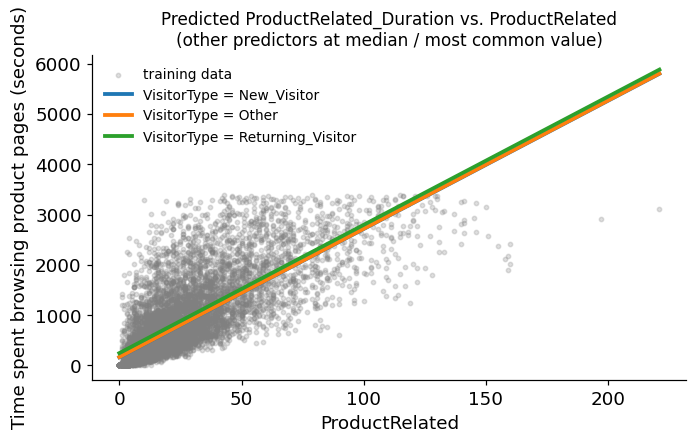

In [49]:
# ✏️ EDIT: an effect plot of one quantitative predictor, one line per category of a qualitative predictor.
# The gaps between the lines are your dummy coefficients. A good figure for your model slide.
fig, ax = plt.subplots(figsize=(6.5, 4.2))
effect_plot(model, OUTCOME_TRANSFORM, x="ProductRelated", by="VisitorType", ax=ax)
plt.tight_layout()
plt.show()

---
# Step 4. Check the assumptions and diagnose problems (you)

Run **every** check here. Only violated assumptions and flagged problems go on your slides; if everything passes, one line on your model slide is enough. Your notebook must still show every check.

### 4a. The four assumptions

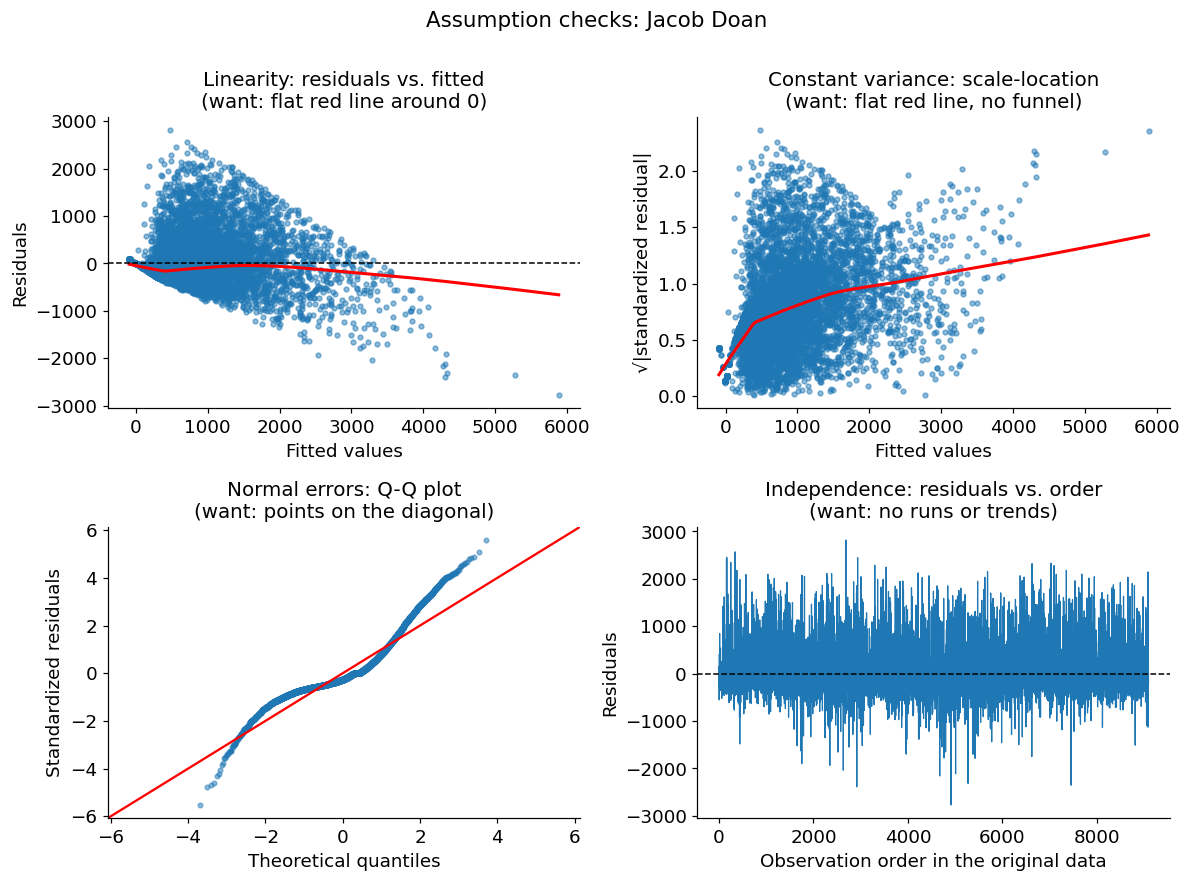

In [50]:
assumption_plots(model, title=f"Assumption checks: {MY_NAME}")

### 4b. Multicollinearity

Needed if your model has 2 or more quantitative predictors. Looks fine when every VIF is below 5, with above 10 serious, and no two predictors are strongly correlated.

Squared and interaction terms are correlated with their parent terms by construction, so high VIFs on them are expected. Centering the predictor first, as in `I(Price - 115)`, reduces them.

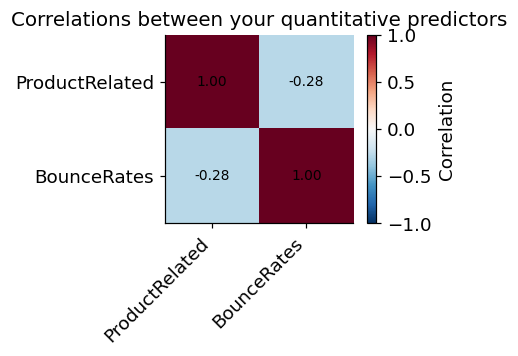

,VIF,flag
C(VisitorType)[T.Other],1.045,
C(VisitorType)[T.Returning_Visitor],1.090,
ProductRelated,1.112,
BounceRates,1.121,


In [51]:
multicollinearity(model)

### 4c. Outliers and high-leverage points

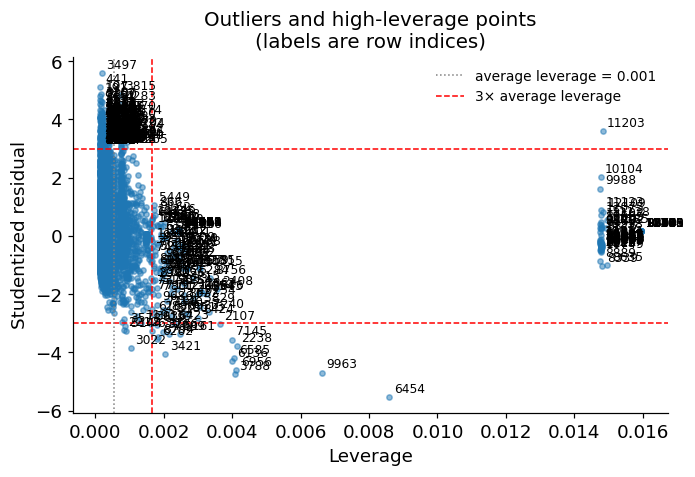

Outliers (|studentized residual| > 3): [10295, 6641, 11769, 2617, 10596, 4665, 1787, 1351, 1346, 9625, 6866, 5615, 11076, 5072, 905, 2207, 9516, 11580, 3497, 3781, 11203, 6303, 1260, 9452, 1393, 12313, 10080, 6956, 3815, 2242, 9024, 3904, 8136, 2238, 6251, 1428, 5161, 8800, 5144, 6015, 9326, 2822, 228, 8596, 5502, 10241, 11703, 8834, 4707, 10204, 459, 7875, 191, 2206, 6393, 10462, 6602, 4983, 4283, 9001, 10265, 3117, 5488, 7653, 2972, 9728, 6734, 441, 567, 8794, 10002, 9879, 9963, 7222, 1822, 133, 6585, 6197, 9357, 1826, 7089, 7388, 1524, 8326, 6370, 1323, 2995, 9080, 1664, 1460, 1320, 3934, 6059, 1540, 10521, 8855, 9818, 8658, 6677, 10858, 10910, 4901, 9738, 11473, 1488, 2212, 8487, 6089, 3311, 2244, 4360, 11911, 3796, 11281, 1605, 4576, 8461, 4591, 2771, 3266, 3070, 5498, 9115, 10564, 10968, 7979, 5953, 7502, 1485, 9912, 11266, 2107, 2945, 11841, 3935, 12163, 5088, 3022, 10658, 2311, 8519, 310, 4917, 3578, 6454, 2647, 3698, 4948, 5831, 488, 1021, 7145, 4867, 3788, 7583, 4456, 197, 67

In [52]:
flagged = outliers_and_leverage(model)

In [53]:
# How much do your coefficients change without the flagged points?
refit_without(model, flagged)

,with all points,without flagged points,% change
BounceRates,-1412.447,-1033.146,26.854
C(VisitorType)[T.Other],4.968,NaN,NaN
C(VisitorType)[T.Returning_Visitor],82.685,59.109,-28.513
Intercept,165.061,99.872,-39.494
ProductRelated,25.502,27.907,9.431


✏️ **Your verdicts.** Satisfied, violated, or unclear, and the plot that tells you.

| Check | Verdict | Evidence (which plot, what you see) |
| --- | --- | --- |
| Linearity | Satisfied | The red smoother line in the residuals vs. fitted plot (top left) sits roughly flat around 0 across the whole range. |
| Constant variance | Violated | The residuals vs. fitted plot (top left) has a fanned shape. The residuals spread out as the fitted values increase. |
| Normal errors | Violated | The points in the data shape is not diagonal on the Q-Q plot (bottom left). They stray far out and curve around it. |
| Independent errors | Satisfied | Assuming rows are independent visitor sessions, there is no pattern in the resudials vs. order plot (bottom right) that suggests the data was collected dependent on each other. The sudden but brief spikes are isolated outliers, not patterns. |
| Multicollinearity | Satisfied | All VIFs are around 1.04 to 1.09, far below the concern threshold of 5. |
| Outliers / high leverage | Violated (in the original dataset) | The outlier/high-leverage plot shows many rows (134) having an absolute studentized residual value greater than 3. Additionally, a considerable number of rows (223) also exceeds 3 times the average leverage. Refitting the model without those high-leverage points (`refit_without`) did not flip the sign of any coefficient. However, the coefficient magnitude of `BounceRates` did change by more than 100% in size, giving me enough reason that those high-leverage points do cause a problem, and therefore justification to remove them. |

### 4d. ✏️ Fix a problem, if you found one (Slide: Problem and fix)

| Problem | Try |
| --- | --- |
| Curved residuals (linearity) | A squared term or a log of a predictor |
| A funnel shape (constant variance) or skewed residuals (normality) | Transform the outcome: `"log"`, `"log1p"`, or `"sqrt"` |
| High VIFs | Drop one of the correlated predictors, or center the predictor |
| An outlier that is a data error | Remove it in Step 1c (tell your group) and refit |

Set the fix below, or leave `FIX_RHS = None` if everything passed.

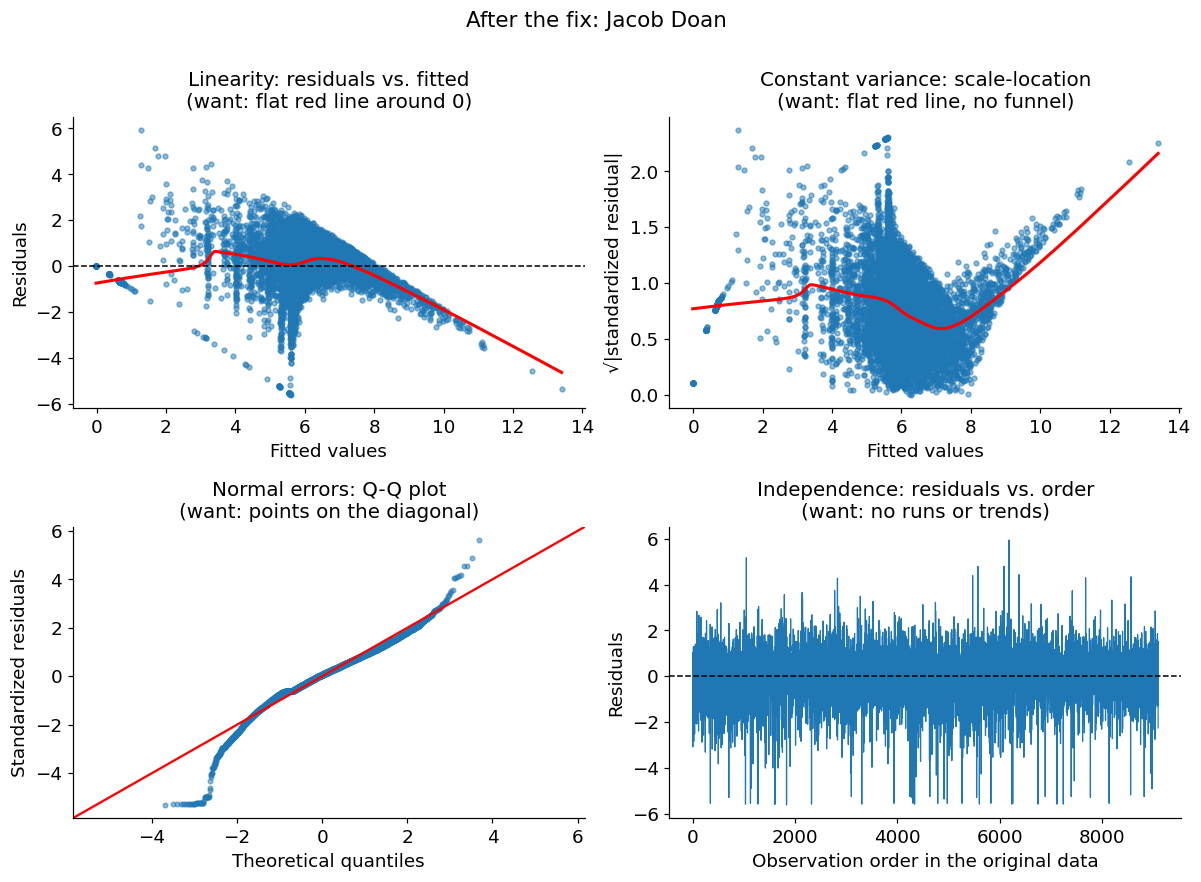

,before,after
Intercept,165.061,5.250
C(VisitorType)[T.Other],4.968,-0.373
C(VisitorType)[T.Returning_Visitor],82.685,0.293
ProductRelated,25.502,0.036
BounceRates,-1412.447,-24.626


Your fixed model is now your final model. Re-run 3a to 3c on it for your slide:


**Your model:**

<IPython.core.display.Math object>

**Fitted equation:**

<IPython.core.display.Math object>

Plain text to paste into your slide:
  log(1+ProductRelated_Duration) = β₀ + β₁·VisitorType[Other] + β₂·VisitorType[Returning_Visitor] + β₃·ProductRelated + β₄·BounceRates + ε
  Predicted log(1+ProductRelated_Duration) = 5.25 − 0.373·VisitorType[Other] + 0.293·VisitorType[Returning_Visitor] + 0.0355·ProductRelated − 24.6·BounceRates


In [54]:
# ✏️ EDIT: your fixed model, or leave as None
FIX_RHS = "ProductRelated + BounceRates + C(VisitorType)" # e.g. RHS + " + I(Price**2)"
FIX_TRANSFORM = 'log1p'       # e.g. "log"

final_model, final_transform = model, OUTCOME_TRANSFORM
if FIX_RHS is None:
    print("No fix: your model from Step 3 is your final model.")
else:
    fixed = smf.ols(build_formula(FIX_RHS, FIX_TRANSFORM), data=train).fit()
    assumption_plots(fixed, title=f"After the fix: {MY_NAME}")
    display(pd.DataFrame({"before": model.params, "after": fixed.params}))
    KEEP_FIX = True   # set to False if the fix didn't help
    if KEEP_FIX:
        final_model, final_transform = fixed, FIX_TRANSFORM
        print("Your fixed model is now your final model. Re-run 3a to 3c on it for your slide:")
        show_equations(final_model, final_transform)

### Fixing more violations

| Check | Verdict | Evidence (which plot, what you see) |
| --- | --- | --- |
| Linearity | Unsatisfied | The red smoother line no longer fits flat around 0 across the whole range (top left plot). Since there are no diminishing returns, we need to add a degree on one of the predictors. |

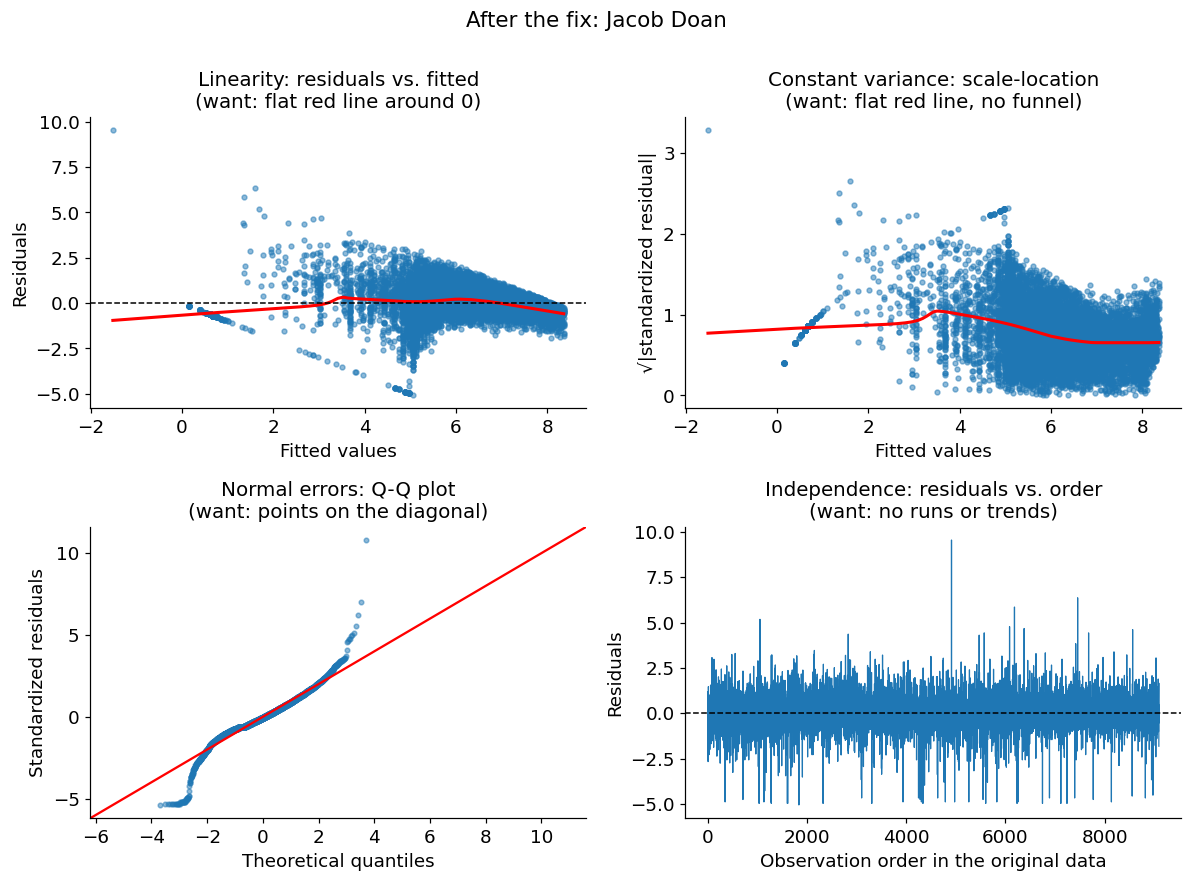

,before,after
BounceRates,-1412.447,-2.182e+01
C(VisitorType)[T.Other],4.968,-2.393e-01
C(VisitorType)[T.Returning_Visitor],82.685,2.171e-01
I(ProductRelated ** 2),NaN,-5.130e-04
Intercept,165.061,4.669e+00
ProductRelated,25.502,8.443e-02


Your fixed model is now your final model. Re-run 3a to 3c on it for your slide:


**Your model:**

<IPython.core.display.Math object>

**Fitted equation:**

<IPython.core.display.Math object>

Plain text to paste into your slide:
  log(1+ProductRelated_Duration) = β₀ + β₁·VisitorType[Other] + β₂·VisitorType[Returning_Visitor] + β₃·ProductRelated + β₄·ProductRelated^2 + β₅·BounceRates + ε
  Predicted log(1+ProductRelated_Duration) = 4.67 − 0.239·VisitorType[Other] + 0.217·VisitorType[Returning_Visitor] + 0.0844·ProductRelated − 0.000513·ProductRelated^2 − 21.8·BounceRates


In [55]:
# ✏️ EDIT: your fixed model, or leave as None
FIX_RHS = "ProductRelated + I(ProductRelated**2) + BounceRates + C(VisitorType)" # e.g. RHS + " + I(Price**2)"
FIX_TRANSFORM = 'log1p'       # e.g. "log"

final_model, final_transform = model, OUTCOME_TRANSFORM
if FIX_RHS is None:
    print("No fix: your model from Step 3 is your final model.")
else:
    fixed = smf.ols(build_formula(FIX_RHS, FIX_TRANSFORM), data=train).fit()
    assumption_plots(fixed, title=f"After the fix: {MY_NAME}")
    display(pd.DataFrame({"before": model.params, "after": fixed.params}))
    KEEP_FIX = True   # set to False if the fix didn't help
    if KEEP_FIX:
        final_model, final_transform = fixed, FIX_TRANSFORM
        print("Your fixed model is now your final model. Re-run 3a to 3c on it for your slide:")
        show_equations(final_model, final_transform)

In [56]:
final_coef_table = pd.DataFrame({"estimate": final_model.params,
                           "95% CI low": final_model.conf_int()[0],
                           "95% CI high": final_model.conf_int()[1],
                           "p-value": final_model.pvalues})
show_baselines(final_model)
final_coef_table

VisitorType: baseline category = New_Visitor; each dummy compares ['Other', 'Returning_Visitor'] with it


,estimate,95% CI low,95% CI high,p-value
Intercept,4.669e+00,4.612e+00,4.727e+00,0.000e+00
C(VisitorType)[T.Other],-2.393e-01,-4.684e-01,-1.023e-02,4.061e-02
C(VisitorType)[T.Returning_Visitor],2.171e-01,1.616e-01,2.726e-01,1.885e-14
ProductRelated,8.443e-02,8.230e-02,8.657e-02,0.000e+00
I(ProductRelated ** 2),-5.130e-04,-5.334e-04,-4.927e-04,0.000e+00
BounceRates,-2.182e+01,-2.224e+01,-2.140e+01,0.000e+00


---
# Step 5. Test your model (you)

Now, and only now, use the test set. Your final model predicts the outcome for every test observation, and we measure how far off it is.

- **Test MSE:** the average squared prediction error, in the outcome's units squared. Lower is better.
- **Test R²:** the share of the test set's variance in the outcome that your model explains. Higher is better.

Both are computed in the outcome's **original units**, even if you transformed it, so every member's numbers can be compared. A test MSE much larger than the training MSE suggests overfitting. Test R² can even be negative: that means the model predicts the test set worse than just guessing the training mean for everyone.

In [57]:
metrics = evaluate(final_model, final_transform)
metrics.to_frame(MY_NAME)

,Jacob Doan
train MSE,451660.053
test MSE,452255.494
train R2,0.293
test R2,0.252


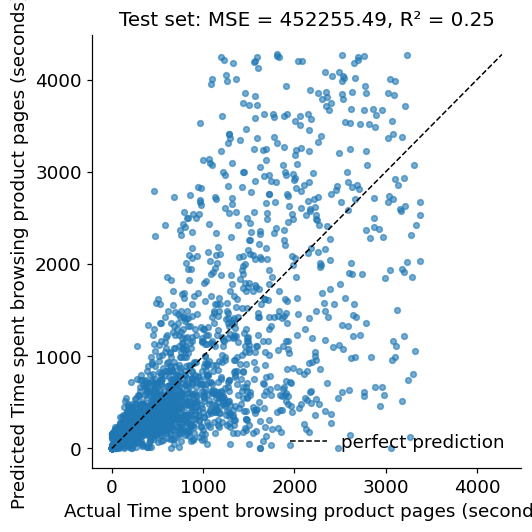

In [58]:
# Predicted vs. actual on the test set
pred_test = back_transform(final_model.predict(test), final_transform)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(test[OUTCOME], pred_test, s=14, alpha=0.6)
lims = [min(test[OUTCOME].min(), pred_test.min()), max(test[OUTCOME].max(), pred_test.max())]
ax.plot(lims, lims, color="black", ls="--", lw=1, label="perfect prediction")
ax.set(xlabel=f"Actual {OUTCOME_LABEL}", ylabel=f"Predicted {OUTCOME_LABEL}",
       title=f"Test set: MSE = {metrics['test MSE']:.2f}, R² = {metrics['test R2']:.2f}")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [59]:
# Your row for the group's comparison table: send this to the member doing Step 6
terms = []
for name in final_model.model.exog_names[1:]:
    term = re.sub(r"\[[^\]]+\]", "", _pretty_term(name, latex=False))   # dummies -> their variable
    if term not in terms:
        terms.append(term)
predictor_list = ", ".join(terms) + ("" if final_transform == "none" else f" ({final_transform} outcome)")
print(f'"{MY_NAME}": ("{predictor_list}", {metrics["test MSE"]:.3f}, {metrics["test R2"]:.3f}),')
print(f"Test set fingerprint: {fingerprint}")

"Jacob Doan": ("VisitorType, ProductRelated, ProductRelated^2, BounceRates (log1p outcome)", 452255.494, 0.252),
Test set fingerprint: 39c7f0e1


---
# Step 6. Compare your models (one member)

One member collects everyone's row from the end of Step 5, pastes them below, and runs these cells. The table and the chart go on your **Model comparison** slide. Check that everyone's test set fingerprint matched.

In [62]:
# ✏️ EDIT: replace these example rows with each member's row from Step 5
results = {
    "Nicholas Chan": ("Weekend, Informational, Administrative, ExitRates", 470653.499, 0.221),
    "Matthew Burger": ("Revenue, ProductRelated, ExitRates", 237291.013, 0.607),
    "Jacob Doan": ("VisitorType, log(1+ProductRelated), BounceRates (log1p outcome)", 452255.494, 0.252),
}

comparison = (pd.DataFrame(results, index=["predictors", "test MSE", "test R2"]).T
              .sort_values("test MSE"))
comparison

,predictors,test MSE,test R2
Matthew Burger,"Revenue, ProductRelated, ExitRates",237291.013,0.607
Jacob Doan,"VisitorType, log(1+ProductRelated), BounceRate...",452255.494,0.252
Nicholas Chan,"Weekend, Informational, Administrative, ExitRates",470653.499,0.221


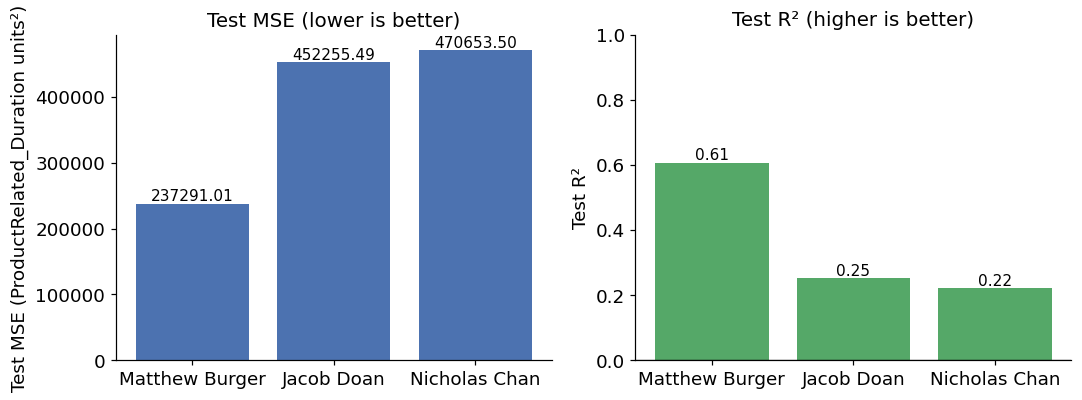

Lowest test MSE: Matthew Burger (MSE = 237291.01, R² = 0.61)


In [63]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(comparison.index, comparison["test MSE"], color="#4C72B0")
axes[0].set(ylabel=f"Test MSE ({OUTCOME} units²)", title="Test MSE (lower is better)")
axes[1].bar(comparison.index, comparison["test R2"], color="#55A868")
axes[1].set(ylabel="Test R²", title="Test R² (higher is better)", ylim=(min(0, comparison["test R2"].min() - 0.05), 1))
axes[1].axhline(0, color="black", lw=0.8)
for ax, col in zip(axes, ["test MSE", "test R2"]):
    for i, v in enumerate(comparison[col]):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=10)
plt.tight_layout()
plt.show()

best = comparison.index[0]
print(f"Lowest test MSE: {best} (MSE = {comparison.loc[best, 'test MSE']:.2f}, "
      f"R² = {comparison.loc[best, 'test R2']:.2f})")

✏️ **Which model predicts best, and why?** One or two sentences for your slide. What does the best model include that the others don't?

-

---
# Before you submit

**This notebook**

- [ ] Steps 1 and 2 match your teammates', and your test set fingerprint matches theirs
- [ ] Your model has at least one quantitative and one qualitative predictor, and different predictors from your teammates'
- [ ] Step 3c interprets one quantitative and one qualitative coefficient, with units and the baseline category
- [ ] Step 4 has every check and your verdict table filled in, including checks that passed
- [ ] **Runtime → Restart and run all** finishes without errors
- [ ] The file is named with your name and saved in your group's Drive folder

**Your slides**

- [ ] Model slide: model in math, fitted equation, key coefficients, both interpretations, test MSE and test R², one line on your checks
- [ ] Problem and fix slide, only if something was violated or flagged
- [ ] Every figure has labeled axes with units

**Your individual form**

- [ ] Contribution statement, including how you used AI tools
- [ ] Answers to the three short questions